In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

In [ ]:
# Generate a synthetic dataset with 300 samples and 2 features
data = make_blobs(n_samples=300, centers=4, n_features=2, random_state=42)

# Standardize the dataset
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data[0])

In [ ]:
def initialize_centroids(data, k):
    """Randomly initialize the centroids from the data points."""
    np.random.seed(42)
    random_indices = np.random.choice(data.shape[0], size=k, replace=False)
    centroids = data[random_indices]
    return centroids

def compute_distances(data, centroids):
    """Compute the distances between each data point and centroids."""
    distances = np.zeros((data.shape[0], centroids.shape[0]))
    for i, centroid in enumerate(centroids):
        distances[:, i] = np.linalg.norm(data - centroid, axis=1)
    return distances

def assign_clusters(distances):
    """Assign each data point to the closest centroid."""
    return np.argmin(distances, axis=1)

def update_centroids(data, clusters, k):
    """Update the centroids by computing the mean of the points in each cluster."""
    new_centroids = np.zeros((k, data.shape[1]))
    for i in range(k):
        cluster_points = data[clusters == i]
        if len(cluster_points) > 0:
            new_centroids[i] = cluster_points.mean(axis=0)
    return new_centroids

def k_means(data, k, max_iterations=100):
    """Implement the K-means clustering algorithm."""
    centroids = initialize_centroids(data, k)
    for _ in range(max_iterations):
        # Step 1: Compute distances from data points to centroids
        distances = compute_distances(data, centroids)

        # Step 2: Assign clusters
        clusters = assign_clusters(distances)

        # Step 3: Update centroids
        new_centroids = update_centroids(data, clusters, k)

        # Step 4: Check for convergence
        if np.allclose(centroids, new_centroids):
            break

        centroids = new_centroids

    return centroids, clusters

In [ ]:
# Choose the number of clusters, K
k = 4

# Run the K-means algorithm
centroids, clusters = k_means(data_scaled, k)

# Compute the total within-cluster sum of squares
wcss = np.sum([np.sum(np.square(data_scaled[clusters == i] - centroids[i])) for i in range(k)])
print("Total within-cluster sum of squares: ", wcss)

Total within-cluster sum of squares:  69.93213076235043


# Visualize the clusters

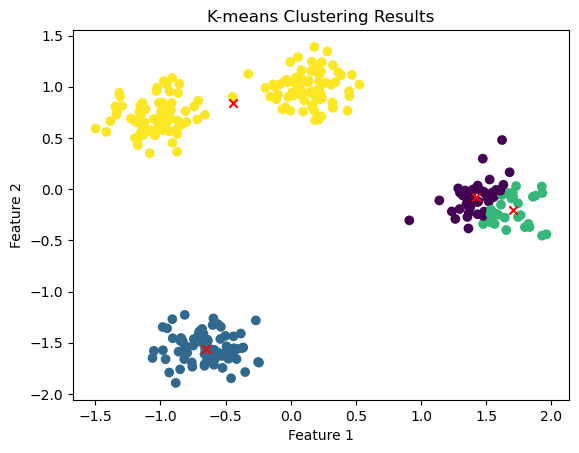

In [ ]:
# Plot the dataset with the assigned clusters and centroids
plt.scatter(data_scaled[:, 0], data_scaled[:, 1], c=clusters, cmap='viridis')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='x')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-means Clustering Results')
plt.show()

In [ ]:
import os
import warnings
os.environ['OMP_NUM_THREADS'] = '2'
warnings.filterwarnings('ignore')

Shape: (440, 8)

First 5 rows:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185



Data Types:
Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

Statistical Summary:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000



Missing Values:
Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Scaled data shape: (440, 6)

K-Means and K-Medoids fitted successfully!

=== K-Means ===
Inertia: 1608.4311
Cluster Centers (scaled):
      Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
0 -0.123436  1.843487  2.181209 -0.181823          2.193481    0.301512
1  0.004957 -0.228048 -0.254553 -0.027068         -0.248890   -0.080143
2  1.803356  3.332987  0.942519  9.409801         -0.446409    8.964157

=== K-Medoids ===
Inertia (computed): 1903.3180
Cluster Centers / Medoids (scaled):
      Fresh      Milk   Grocery    Frozen  Detergents_Paper  Delicassen
0 -0.474497  0.718495  1.151423 -0.394488          0.954031    0.203461
1 -0.473231 -0.331290 -0.494111 -0.116501         -0.560531   -0.297799
2  0.560970 -0.609370 -0.453868 -0.005554         -0.455963   -0.22253

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


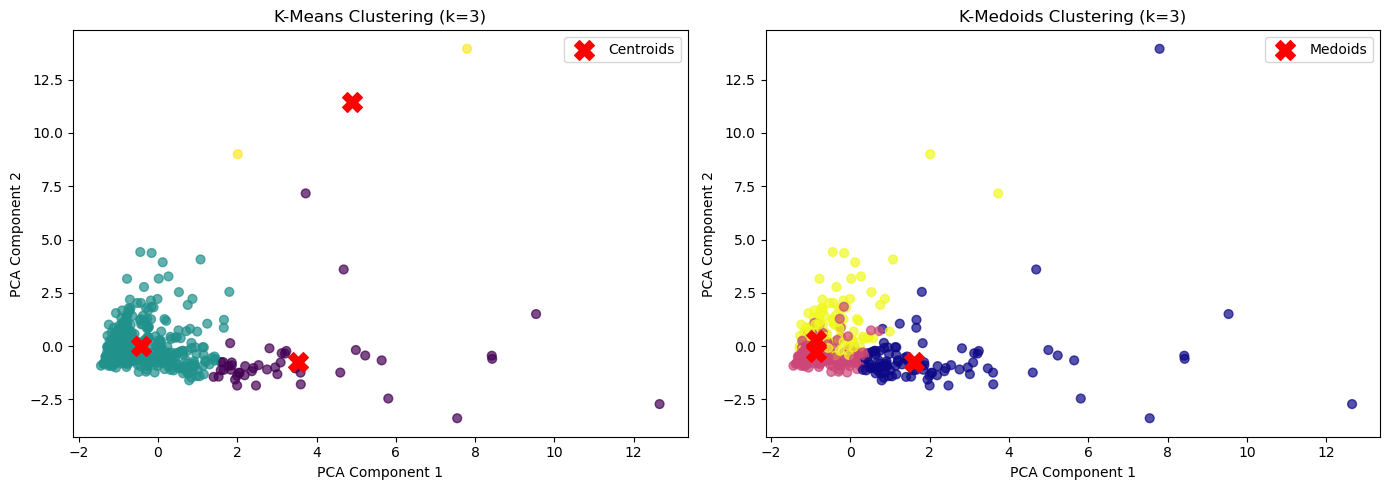

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(
C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Window

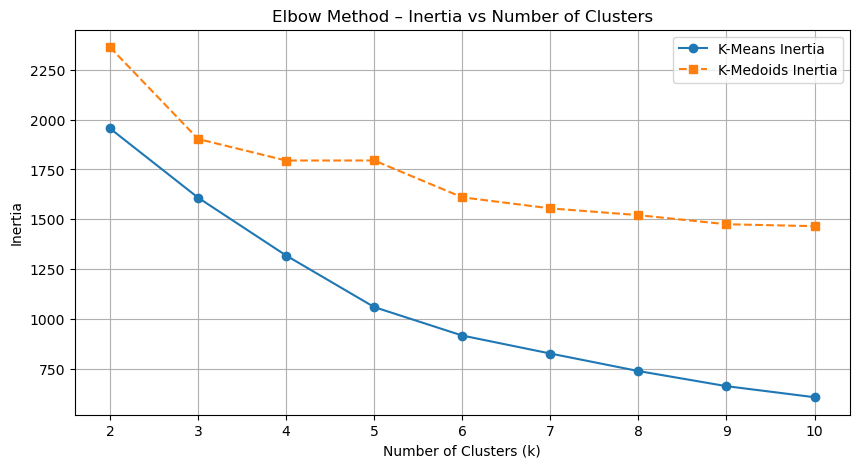

Best k = 3

K-Means cluster distribution:
KMeans_Cluster
0     45
1    393
2      2
Name: count, dtype: int64

K-Medoids cluster distribution:
KMedoids_Cluster
0    103
1    200
2    137
Name: count, dtype: int64

Sample predictions (first 10 rows):


C:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1429: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


,Channel,Region,KMeans_Cluster,KMedoids_Cluster
0,2,3,1,1
1,2,3,1,0
2,2,3,1,0
3,1,3,1,2
4,2,3,1,2
5,2,3,1,1
6,2,3,1,1
7,2,3,1,1
8,1,3,1,1
9,2,3,0,0


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn_extra.cluster import KMedoids
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# ── Step 1: Explore the Dataset ──────────────────────────────────────────────
df = pd.read_csv('Wholesale customers data.csv')
print('Shape:', df.shape)
print('\nFirst 5 rows:')
display(df.head())
print('\nData Types:')
print(df.dtypes)
print('\nStatistical Summary:')
display(df.describe())
print('\nMissing Values:')
print(df.isnull().sum())

# ── Step 3: Standardize the Data ─────────────────────────────────────────────
features = df.drop(columns=['Channel', 'Region'])
scaler = StandardScaler()
data_scaled = scaler.fit_transform(features)
print('\nScaled data shape:', data_scaled.shape)

# ── Step 4: Fit K-Means and K-Medoids (k=3) ──────────────────────────────────
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(data_scaled)
kmedoids = KMedoids(n_clusters=k, random_state=42)
kmedoids.fit(data_scaled)
print('\nK-Means and K-Medoids fitted successfully!')

# ── Step 5: Cluster Centers and Inertia ──────────────────────────────────────
print('\n=== K-Means ===')
print(f'Inertia: {kmeans.inertia_:.4f}')
print('Cluster Centers (scaled):')
print(pd.DataFrame(kmeans.cluster_centers_, columns=features.columns))

kmedoids_inertia = sum(
    np.sum((data_scaled[kmedoids.labels_ == i] - kmedoids.cluster_centers_[i])**2)
    for i in range(k)
)
print('\n=== K-Medoids ===')
print(f'Inertia (computed): {kmedoids_inertia:.4f}')
print('Cluster Centers / Medoids (scaled):')
print(pd.DataFrame(kmedoids.cluster_centers_, columns=features.columns))

# ── Step 6: Visualize Clusters ────────────────────────────────────────────────
pca = PCA(n_components=2, random_state=42)
data_2d = pca.fit_transform(data_scaled)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

centers_2d_km = pca.transform(kmeans.cluster_centers_)
axes[0].scatter(data_2d[:, 0], data_2d[:, 1], c=kmeans.labels_, cmap='viridis', s=40, alpha=0.7)
axes[0].scatter(centers_2d_km[:, 0], centers_2d_km[:, 1], c='red', marker='X', s=200, label='Centroids')
axes[0].set_title('K-Means Clustering (k=3)')
axes[0].set_xlabel('PCA Component 1')
axes[0].set_ylabel('PCA Component 2')
axes[0].legend()

centers_2d_kmd = pca.transform(kmedoids.cluster_centers_)
axes[1].scatter(data_2d[:, 0], data_2d[:, 1], c=kmedoids.labels_, cmap='plasma', s=40, alpha=0.7)
axes[1].scatter(centers_2d_kmd[:, 0], centers_2d_kmd[:, 1], c='red', marker='X', s=200, label='Medoids')
axes[1].set_title('K-Medoids Clustering (k=3)')
axes[1].set_xlabel('PCA Component 1')
axes[1].set_ylabel('PCA Component 2')
axes[1].legend()

plt.tight_layout()
plt.show()

# ── Step 7: Elbow Method ──────────────────────────────────────────────────────
inertias_km, inertias_kmd = [], []
k_range = range(2, 11)

for k_val in k_range:
    km = KMeans(n_clusters=k_val, random_state=42, n_init=10)
    km.fit(data_scaled)
    inertias_km.append(km.inertia_)

    kmd = KMedoids(n_clusters=k_val, random_state=42)
    kmd.fit(data_scaled)
    inertias_kmd.append(sum(
        np.sum((data_scaled[kmd.labels_ == i] - kmd.cluster_centers_[i])**2)
        for i in range(k_val)
    ))

plt.figure(figsize=(10, 5))
plt.plot(list(k_range), inertias_km,  marker='o', label='K-Means Inertia')
plt.plot(list(k_range), inertias_kmd, marker='s', linestyle='--', label='K-Medoids Inertia')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia')
plt.title('Elbow Method – Inertia vs Number of Clusters')
plt.xticks(list(k_range))
plt.legend()
plt.grid(True)
plt.show()

# ── Step 8: Predictions Using Best k ─────────────────────────────────────────
best_k = 3  # update after inspecting the elbow plot above

best_kmeans   = KMeans(n_clusters=best_k, random_state=42, n_init=10)
best_kmedoids = KMedoids(n_clusters=best_k, random_state=42)
km_labels  = best_kmeans.fit_predict(data_scaled)
kmd_labels = best_kmedoids.fit_predict(data_scaled)

df_result = df.copy()
df_result['KMeans_Cluster']   = km_labels
df_result['KMedoids_Cluster'] = kmd_labels

print(f'Best k = {best_k}')
print('\nK-Means cluster distribution:')
print(df_result['KMeans_Cluster'].value_counts().sort_index())
print('\nK-Medoids cluster distribution:')
print(df_result['KMedoids_Cluster'].value_counts().sort_index())
print('\nSample predictions (first 10 rows):')
display(df_result[['Channel', 'Region', 'KMeans_Cluster', 'KMedoids_Cluster']].head(10))